# 06. 가상 A/B 테스트 설계서 — 데이터만 받으러 온 신규 유저에게 진행 중 대회를 추천하면 참여가 늘어나는가

## 1페이지 요약

| 항목 | 내용 |
|---|---|
| **질문 (인과)** | 끝난 대회에만 참가한 신규 유저에게 **진행 중 대회 추천**을 보내면, 보내지 않았을 때보다 30일 안에 대회에 제출하는 비율이 오르는가 |
| **대상** | 가입 후 D+14 시점에 ① 끝난 대회에만 참가했고 ② D 활동이 없고 ③ 노트북을 쓰지 않은 유저. 월 약 6,100명 (D+14 모델 대상의 33%) |
| **실험군 (처치)** | D+15에 "지금 참가할 수 있는 대회 3개" 추천 메일 + 사이트 알림 1회 |
| **대조군** | 아무것도 보내지 않음 (평소와 동일) |
| **배정** | 유저 단위 무작위, **실험군 50% : 대조군 50%**, D+14 모델 점수 10분위로 층화 |
| **주 지표** | D+15 ~ D+44 (처치 후 30일) 대회 제출 여부. 현재 기준값 1.56% |
| **보조 지표** | D+15 ~ D+90 D 활동 (2.97%), 30일 안 진행 중 대회 참가 |
| **가드레일** | 메일 수신 거부율 (절대 +0.5%p 이하), 90일 QAU 활동 비열등성 (−5% 이내) |
| **표본·기간** | 상대 +30% 효과(1.56% → 2.03%)를 검정력 80%로 잡으려면 군당 약 1.26만 명 → **약 4개월 모집 + 30일 관찰**. 모델 점수로 보정(CUPED)해도 분산은 2.5%만 줄어 기간은 거의 같다 (§7) |
| **추정 대상** | 배정 기준 평균 효과(ITT). 메일을 연 사람에 대한 효과(CACE)는 보조 |
| **판단** | 주 지표 개선의 95% CI 하한 > 0 **그리고** 가드레일 통과 → 확대. 효과가 모델 점수 구간에 따라 다르면 효과 큰 구간에만 적용 |

**왜 실험이 필요한가**: 관찰 데이터에서는 진행 중 대회 참가자의 전환율(9.4%)이 끝난 대회만 참가한 사람(3.0%)보다 3배 높다. 하지만 원래 의지가 큰 사람이 진행 중 대회를 골랐을 수 있다(자기 선택). 이 차이가 **추천으로 만들어낼 수 있는 효과**인지는 관찰 데이터로 알 수 없다. 무작위 배정만이 이 질문에 답한다.

입력: `data/processed/ml_dataset.parquet`, MySQL `ml_events` (기준값 계산용)

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest
from sqlalchemy import text

sys.path.append("../src")
sys.path.append(os.path.expanduser("~/.claude/skills/chart-style"))
from metakaggle.config import processed, SEED
from metakaggle.db import get_engine
import viz_style as vs

vs.setup()
FIG = "../docs/figures"
data = pd.read_parquet(processed("ml_dataset"))
model_df = data[(data.period == "Stagnation") & (data.segment == "model")]
ev = pd.read_sql(text("select UserId, day, type from ml_events where type in ('submission', 'team') and day between 15 and 90"), get_engine())

## 1. 인과 질문

**잠재적 결과(potential outcomes)로 쓰면**: 유저 $i$마다 두 결과가 있다고 본다.
- $Y_i(1)$: 추천을 **받았을 때** 30일 안에 제출하는가
- $Y_i(0)$: 추천을 **받지 않았을 때** 제출하는가

알고 싶은 것은 **평균 처치 효과** $\text{ATE} = E[Y(1) - Y(0)]$다. 한 사람에게서는 둘 중 하나만 관측되므로, 무작위 배정으로 두 집단이 처치 외에는 같도록 만들어 $E[Y \mid \text{실험군}] - E[Y \mid \text{대조군}]$로 추정한다.

**관찰 데이터로 안 되는 이유**: "진행 중 대회 참가자 9.4% vs 끝난 대회만 3.0%"는 **누가 진행 중 대회를 골랐나**(의지, 실력, 목적)가 섞인 비교다. 이 선택을 무작위 배정이 끊는다.

## 2. 대상 (적격 기준)

| 구분 | 기준 | 이유 |
|---|---|---|
| 포함 | 가입 후 14일이 지난 신규 유저 | 5편 모델과 같은 판단 시점 |
| 포함 | D+14까지 대회에 참가했고, **참가한 대회가 모두 마감이 지난 대회** | 데이터를 받으러 온 유저 (5편: 끝난 대회 참가 = 데이터 다운로드) |
| 제외 | D+14까지 D 활동(노트북 공개, 제출, 포럼 글, 데이터셋·모델)이 있음 | 이미 핵심 창작을 시작함 |
| 제외 | D+14까지 노트북 작성 | 규칙 그룹 (전환율 59%), 별도 관리 |
| 제외 | D+14까지 대회 참가 10개 초과 | 자동화 계정 의심 (99%가 3개 이하) |
| 제외 | 메일 수신 거부 상태 | 처치를 전달할 수 없음 |
| 제외 | 같은 기간 다른 온보딩 실험에 배정됨 | 실험 간 간섭 방지 |

In [2]:
elig = model_df[(model_df.n_teams > 0) & (model_df.share_closed_comps == 1) & (model_df.n_teams <= 10)].copy()
sub = ev[(ev.type == "submission") & ev.day.between(15, 44)].UserId.unique()
elig["sub30"] = elig.UserId.isin(sub).astype(int)     # 주 지표: 처치 후 30일 (D+15 ~ D+44) 대회 제출
monthly = elig.groupby("cohort_month").agg(인원=("UserId", "size"), 제출_30일=("sub30", "mean"), D전환_90일=("y", "mean"))
BASE_P, BASE_Y, MONTHLY_N = elig.sub30.mean(), elig.y.mean(), monthly["인원"].mean()
print(f"월 평균 대상 {MONTHLY_N:,.0f}명 (D+14 모델 대상의 {len(elig) / len(model_df):.0%}), 30일 제출 {BASE_P:.2%}, 90일 D 전환 {BASE_Y:.2%}")
monthly.style.format({"인원": "{:,}", "제출_30일": "{:.2%}", "D전환_90일": "{:.2%}"})

월 평균 대상 6,142명 (D+14 모델 대상의 33%), 30일 제출 1.56%, 90일 D 전환 2.97%


,인원,제출_30일,D전환_90일
cohort_month,,,
2024-07,"6,168",1.28%,2.22%
2024-08,"5,863",1.01%,2.20%
2024-09,"7,173",1.41%,3.39%
2024-10,"8,011",2.05%,3.56%
2024-11,"7,378",1.88%,2.81%
2024-12,"5,948",0.96%,1.88%
2025-01,"4,721",1.40%,3.01%
2025-02,"5,681",1.27%,2.80%
2025-03,"7,313",1.50%,3.21%


## 3. 처치와 대조 (정확한 정의)

| | **실험군 (Treatment)** | **대조군 (Control)** |
|---|---|---|
| 받는 것 | **D+15 오전 9시(유저 현지 시각)** "지금 참가할 수 있는 대회 3개" 메일 1통 + 사이트 상단 알림 1회 (D+15 ~ D+21 노출) | 없음. 평소 시스템 메일(가입 확인 등)만 |
| 추천 대회 3개 고르는 규칙 | ① 마감까지 30일 이상 남은 진행 중 대회만 ② 1개는 Playground Series(입문용) ③ 2개는 유저가 참가했던 끝난 대회와 **태그가 겹치는** 진행 중 대회 (없으면 참가 팀 수 상위) | — |
| 메시지 | "○○ 데이터로 이미 연습하셨네요. 지금 열려 있는 비슷한 대회에서 순위를 확인해 보세요" + 대회별 마감일·참가자 수 | — |
| 빈도 제한 | 실험 기간 1인 1회 | — |
| 다른 메일 | 두 군 모두 평소와 동일 (실험 기간 다른 마케팅 메일은 두 군에 똑같이) | 동일 |

**배정 방식**
- 단위: 유저 (같은 유저는 끝까지 같은 군)
- 방법: D+14 모델 점수 10분위 안에서 `hash(UserId + 실험이름) mod 100` < 50 → 실험군, 나머지 → 대조군. 층화로 두 군의 점수 분포를 같게 맞춘다
- 비율: **50 : 50**. 같은 총인원에서 검정력이 가장 높다 (§6에서 80 : 20과 비교)
- 배정 시점: D+14 판정 직후, 처치 전. 배정 로그를 남긴다

**왜 "아무것도 안 보냄"이 대조군인가**: 결정하려는 것은 "이 추천을 보낼 것인가"다. 그래서 비교 대상은 보내지 않는 현재 상태다. "메일을 받았다는 사실"과 "추천 내용"의 효과를 나누려면 대조군을 "일반 안내 메일"로 두는 3군 설계가 필요하다(§10). 대상 규모상 1차 실험은 2군으로 한다.

## 4. 추정 대상 (Estimand)

| | 정의 | 언제 쓰나 |
|---|---|---|
| **ITT (주)** | 배정된 그대로 비교: 실험군 전체 − 대조군 전체 (메일을 안 열었어도 실험군) | "이 정책을 켜면 대상 전체에서 얼마나 오르나" — 실제 의사결정 단위 |
| CACE (보조) | 메일을 **열 사람**에 대한 효과 = ITT ÷ (실험군 열람률). 배정을 도구변수로 쓰는 추정 | "추천 자체의 효과"가 궁금할 때. 대조군에는 메일이 없으므로 one-sided 비순응 |

메일을 연 사람끼리만 비교하면 안 된다: 여는 사람은 원래 활동적인 사람이라 무작위 배정의 장점이 사라진다.

## 5. 지표

| 종류 | 지표 | 정의 | 기준값 | 판정 |
|---|---|---|---|---|
| **주** | 30일 대회 제출 | D+15 ~ D+44에 대회 제출(팀 제출 포함) | 1.56% | 양측 α = 0.05 |
| 보조 | 90일 D 전환 | D+15 ~ D+90 D 활동 | 2.97% | Holm 보정 |
| 보조 | 30일 진행 중 대회 참가 | D+15 ~ D+44에 마감 전 대회 팀 합류 | 측정 예정 | Holm 보정 |
| 가드레일 | 메일 수신 거부율 | 실험군 − 대조군 | 사전 측정 | 절대 +0.5%p 넘으면 중단 |
| 가드레일 | 90일 QAU 활동 | D+15 ~ D+90 참여·창작 활동 여부 | — | **비열등성**: 실험군/대조군 비율의 95% CI 하한 > 0.95 |

**주 지표를 90일 D 전환이 아니라 30일 제출로 정한 이유**: ① 추천의 직접 경로(추천 → 참가 → 제출)에 있는 지표라 효과가 먼저, 크게 나타난다 ② 90일을 기다리면 의사결정이 4개월 늦어진다 ③ 제출은 D 활동의 한 종류라 90일 D 전환과 이어진다.

**가드레일을 비열등성으로 두는 이유**: "나빠지지 않았다"는 유의하지 않음으로는 보일 수 없다 (01편 동등성 검정과 같은 논리). 한쪽 마진(−5%)을 정해 그보다 나쁘지 않음을 입증한다.

## 6. 표본 크기와 기간

양측 α = 0.05, 검정력 80%, 기준값 1.56%. 상대 효과(MDE)별로 군당 필요 인원과 모집 기간을 계산한다.

In [3]:
power = NormalIndPower()
def n_per_arm(p0, rel, ratio=1.0):
    """ratio = 대조군/실험군 인원 비. 반환: (실험군, 대조군) 필요 인원"""
    es = proportion_effectsize(p0 * (1 + rel), p0)
    n1 = power.solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=ratio, alternative="two-sided")
    return n1, n1 * ratio

rows = []
for rel in [0.15, 0.20, 0.25, 0.30, 0.40]:
    for split, ratio in [("50 : 50", 1.0), ("80 : 20", 0.25)]:
        n1, n0 = n_per_arm(BASE_P, rel, ratio)
        rows.append({"상대 효과": f"+{rel:.0%}", "기대 제출률": f"{BASE_P:.2%} → {BASE_P * (1 + rel):.2%}", "실험군:대조군": split,
                     "실험군": n1, "대조군": n0, "총 인원": n1 + n0, "모집 기간(월)": (n1 + n0) / MONTHLY_N})
size = pd.DataFrame(rows)
size.style.format({"실험군": "{:,.0f}", "대조군": "{:,.0f}", "총 인원": "{:,.0f}", "모집 기간(월)": "{:.1f}"})

,상대 효과,기대 제출률,실험군:대조군,실험군,대조군,총 인원,모집 기간(월)
0,+15%,1.56% → 1.79%,50 : 50,"47,190","47,190","94,379",15.4
1,+15%,1.56% → 1.79%,80 : 20,"117,974","29,494","147,468",24.0
2,+20%,1.56% → 1.87%,50 : 50,"27,128","27,128","54,256",8.8
3,+20%,1.56% → 1.87%,80 : 20,"67,820","16,955","84,774",13.8
4,+25%,1.56% → 1.95%,50 : 50,"17,731","17,731","35,463",5.8
5,+25%,1.56% → 1.95%,80 : 20,"44,328","11,082","55,410",9.0
6,+30%,1.56% → 2.03%,50 : 50,"12,567","12,567","25,135",4.1
7,+30%,1.56% → 2.03%,80 : 20,"31,418","7,855","39,273",6.4
8,+40%,1.56% → 2.19%,50 : 50,"7,351","7,351","14,702",2.4
9,+40%,1.56% → 2.19%,80 : 20,"18,377","4,594","22,971",3.7


- **50 : 50을 쓴다.** 80 : 20은 같은 검정력에 총인원이 약 1.6배 필요하다 (모집 기간도 1.6배). 사업적으로 "대부분에게 빨리 보내고 싶다"면 80 : 20을 쓸 수 있지만, 그만큼 늦게 결론이 난다.
- **목표 MDE = +30%** (1.56% → 2.03%): 군당 약 1.26만 명, **약 4개월 모집**. 메일 한 통 개입에서 30%는 큰 효과라 낙관적인 목표다. +20%를 잡으려면 약 9개월이 필요하다 → 4개월 안에 결론이 나지 않으면 "+30% 이상의 큰 효과는 없다"까지만 말할 수 있다는 점을 미리 합의한다.
- 모집은 **월 단위로 끊지 않고 연속**으로 한다. 4개월에 걸치면 대회 일정·계절 차이가 두 군에 똑같이 섞인다.

## 7. 모델 점수로 분산 줄이기 (CUPED)

5편 모델의 D+14 점수는 **처치 전에** 정해지는 값이라 처치의 영향을 받지 않는다. 결과를 이 점수로 보정하면 결과의 분산이 $(1 - \rho^2)$배로 줄고, 같은 검정력에 필요한 인원도 그만큼 준다 ($\rho$ = 점수와 결과의 상관).

과거 데이터로 $\rho$를 추정한다: 5편과 같은 피처로 2024-07 ~ 2025-03 가입자에게 학습하고, 2025-04 ~ 09 대상자에게 점수를 매겨 30일 제출과의 상관을 본다.

In [4]:
FEATS = ["n_follow", "n_vote_model", "n_vote_dataset", "n_vote_forum", "n_reaction", "n_team", "n_teams", "n_light", "n_light_types",
         "active_days", "first_day", "last_day", "recency", "active_d0", "active_d1_7", "active_d8_14", "reg_weekday",
         "first_is_team", "light_only", "max_team_size_d14", "first_team_day", "min_days_to_deadline", "max_reward",
         "comp_featured", "comp_research", "comp_playground", "comp_community", "comp_getting_started",
         "n_followed_by", "n_closed_comps", "n_open_comps", "share_closed_comps", "max_comp_teams_at_join_open", "min_comp_age",
         "any_kernels_only", "any_playground_series", "any_joined_others_team", "first_reward_usd", "first_reward_knowledge"]
past = model_df[model_df.cohort_month <= "2025-03"]
m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, random_state=SEED, verbose=-1).fit(past[FEATS], past.y)
later = elig[elig.cohort_month >= "2025-04"].copy()
later["score"] = m.predict_proba(later[FEATS])[:, 1]
rho = np.corrcoef(later.score, later.sub30)[0, 1]
print(f"점수-30일 제출 상관 ρ = {rho:.3f} → 분산 {1 - rho ** 2:.1%}로 감소, 필요 인원 {rho ** 2:.1%} 절감")
print(f"(참고) 점수-90일 D 전환 상관 ρ = {np.corrcoef(later.score, later.y)[0, 1]:.3f}")
size["CUPED 적용 모집 기간(월)"] = size["모집 기간(월)"] * (1 - rho ** 2)
size[size["실험군:대조군"] == "50 : 50"][["상대 효과", "총 인원", "모집 기간(월)", "CUPED 적용 모집 기간(월)"]].style.format(
    {"총 인원": "{:,.0f}", "모집 기간(월)": "{:.1f}", "CUPED 적용 모집 기간(월)": "{:.1f}"})

점수-30일 제출 상관 ρ = 0.159 → 분산 97.5%로 감소, 필요 인원 2.5% 절감
(참고) 점수-90일 D 전환 상관 ρ = 0.162


,상대 효과,총 인원,모집 기간(월),CUPED 적용 모집 기간(월)
0,+15%,"94,379",15.4,15.0
2,+20%,"54,256",8.8,8.6
4,+25%,"35,463",5.8,5.6
6,+30%,"25,135",4.1,4.0
8,+40%,"14,702",2.4,2.3


[]


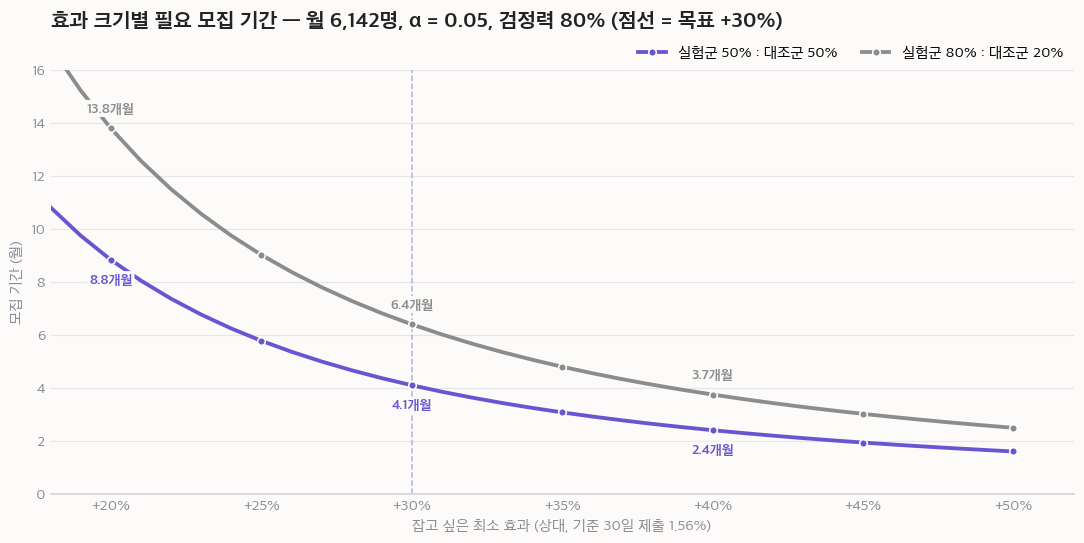

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
rels = np.linspace(0.15, 0.50, 36)
months = np.array([sum(n_per_arm(BASE_P, r)) / MONTHLY_N for r in rels])
months_82 = np.array([sum(n_per_arm(BASE_P, r, 0.25)) / MONTHLY_N for r in rels])
idx = [5, 10, 15, 20, 25, 30, 35]
vs.line(ax, rels, months, vs.PURPLE, "실험군 50% : 대조군 50%", markevery=idx)
vs.line(ax, rels, months_82, vs.GRAY, "실험군 80% : 대조군 20%", markevery=idx)
for i in [5, 15, 25]:
    for arr, c, dy in [(months, vs.PURPLE, -16), (months_82, vs.GRAY, 10)]:
        ax.annotate(f"{arr[i]:.1f}개월", (rels[i], arr[i]), xytext=(0, dy), textcoords="offset points", ha="center", color=c, fontsize=9, fontweight="bold", bbox=vs.LABEL_BOX)
ax.axvline(0.30, color=vs.LAVENDER, ls="--", lw=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"+{v:.0%}"))
ax.set_xlabel("잡고 싶은 최소 효과 (상대, 기준 30일 제출 1.56%)"); ax.set_ylabel("모집 기간 (월)")
ax.set_ylim(0, 16); ax.set_xlim(0.18, 0.52)
ax.set_title(f"효과 크기별 필요 모집 기간 — 월 {MONTHLY_N:,.0f}명, α = 0.05, 검정력 80% (점선 = 목표 +30%)", loc="left", fontweight="bold", pad=28)
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/06_power_duration.png", dpi=120, bbox_inches="tight"); print(vs.check_overlaps(fig))

**→ 분산 감소는 작다 (약 2.5%).** 30일 제출이 1.6%로 드문 사건이고, 모델은 90일 D 전환을 맞히도록 학습돼 상관이 약하다. 그래서 이 실험에서 모델 점수의 주된 쓰임은 분산 감소가 아니라 **① 층화 배정(두 군의 점수 분포 일치) ② 사전 지정한 효과 이질성 분석(점수 구간별 효과 → 타깃팅)**이다. CUPED 보정은 비용이 없으니 분석에는 넣되, 기간 계산에는 반영하지 않는다.

## 8. 실험 전 점검: A/A 시뮬레이션

설계한 배정·분석 절차가 **효과가 없을 때 거짓 양성을 5%만 내는지** 과거 데이터로 확인한다. 처치 없이 대상자를 같은 방식(점수 10분위 층화, 50 : 50)으로 1,000번 나눠 주 지표를 검정한다.

In [6]:
rng = np.random.default_rng(SEED)
later["decile"] = pd.qcut(later.score.rank(method="first"), 10, labels=False)
pvals, smd = [], []
for _ in range(1000):
    t = later.groupby("decile").cumcount().values  # 층 안에서 섞은 뒤 절반씩
    order = later.groupby("decile").score.transform(lambda s: rng.permutation(len(s)))
    treat = (order < later.groupby("decile").score.transform("size") / 2).values
    y1, y0 = later.sub30.values[treat], later.sub30.values[~treat]
    pvals.append(proportions_ztest([y1.sum(), y0.sum()], [len(y1), len(y0)])[1])
    s1, s0 = later.score.values[treat], later.score.values[~treat]
    smd.append((s1.mean() - s0.mean()) / np.sqrt((s1.var() + s0.var()) / 2))
pvals = np.array(pvals)
print(f"[층 무시한 z검정] A/A 거짓 양성률 {(pvals < 0.05).mean():.1%} (기대 5%), p값 균등성 KS p = {stats.kstest(pvals, 'uniform').pvalue:.3f}")
print(f"점수 표준화 평균차 최대 {np.abs(smd).max():.3f} (기준 < 0.1)")

# 층별 차이를 층 크기로 가중 평균하는 층화 추정량 (분석 계획 §9와 같은 구조)
dec, yv = later.decile.values, later.sub30.values
pv_s = []
for _ in range(1000):
    order = later.groupby("decile").score.transform(lambda s: rng.permutation(len(s))).values
    treat = order < later.groupby("decile").score.transform("size").values / 2
    est = var = 0.0
    for k in range(10):
        mk = dec == k; a, b = yv[mk & treat], yv[mk & ~treat]; w = mk.mean()
        est += w * (a.mean() - b.mean()); var += w ** 2 * (a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    pv_s.append(2 * stats.norm.sf(abs(est) / np.sqrt(var)))
pv_s = np.array(pv_s)
print(f"[층화 추정량] A/A 거짓 양성률 {(pv_s < 0.05).mean():.1%} (기대 5%)")

[층 무시한 z검정] A/A 거짓 양성률 3.5% (기대 5%), p값 균등성 KS p = 0.004
점수 표준화 평균차 최대 0.021 (기준 < 0.1)


[층화 추정량] A/A 거짓 양성률 5.0% (기대 5%)


**→ 해석**: 층을 무시한 단순 z검정은 거짓 양성이 5%보다 적게 나온다 (보수적). 층화 배정으로 두 군이 이미 비슷하게 맞춰졌는데 검정은 그 효과를 모르기 때문이다. 보수적이면 안전하지만 검정력을 잃는다. 그래서 주 분석은 **층을 반영한 추정**(§9 회귀의 점수 10분위 항, 또는 층화 추정량)으로 한다. 결과가 드문 0/1 사건이라 p값 분포가 매끈한 균등분포가 되지는 않는다.

**실험 중 매일 확인**
- **표본 비율 불일치(SRM)**: 실제 배정 비율이 50 : 50에서 벗어나는지 χ² 검정. p < 0.001이면 배정·로깅 오류로 보고 분석을 멈춘다
- **공변량 균형**: 모델 점수, 대회 참가 수, 가입 요일의 표준화 평균차 < 0.1
- **가드레일**: 수신 거부율. 기준을 넘으면 중단

## 9. 분석 계획 (실험 전에 고정)

| 단계 | 방법 |
|---|---|
| 주 분석 | ITT: 실험군 − 대조군 30일 제출률 차이와 95% CI. **CUPED 보정**: $Y_i - \theta(\text{score}_i - \overline{\text{score}})$, $\theta$ = 두 군을 합친 회귀 계수 |
| 같은 결과를 회귀로 | `제출 ~ 처치 + 모델 점수 + 점수 10분위` (선형 확률 모형, 강건 표준오차) |
| 보조 지표 | 같은 방식. 보조 2개에 Holm 보정 |
| CACE | ITT ÷ 실험군 메일 열람률 (Wald 추정, 대조군 열람 = 0) |
| 효과 이질성 (사전 지정 1개) | 모델 점수 3분위(하·중·상)별 효과. 상호작용 항 `처치 × 점수 구간`. **사전에 정한 이 하나만** 확정적으로 해석하고, 나머지 세분화는 탐색으로만 |
| 중간 확인 | 가드레일만. 주 지표는 정한 인원이 다 모일 때까지 보지 않는다 (중간에 보고 멈추면 거짓 양성이 늘어난다) |

**의사결정 규칙**

| 결과 | 결정 |
|---|---|
| 주 지표 95% CI 하한 > 0, 가드레일 통과 | 대상 전체로 확대 |
| 효과가 점수 상위 구간에서만 유의 | 상위 구간에만 적용 (모델을 타깃팅에 사용) |
| 주 지표 CI가 0을 포함 | 이 추천 방식은 보류. 3군 설계(§10)나 다른 처치(노트북 시작 유도)로 |
| 가드레일 실패 | 즉시 중단, 메시지·빈도 재설계 |

## 10. 인과 가정과 위협 요인

| 가정 / 위협 | 내용 | 대응 |
|---|---|---|
| **무작위 배정 (교환 가능성)** | 두 군은 처치 외에는 같아야 함 | 해시 기반 배정, 점수 층화, SRM·균형 점검 (§8) |
| **SUTVA: 간섭 없음** | 한 유저의 처치가 다른 유저 결과에 영향을 주면 안 됨. 실험군이 대조군 친구를 팀에 초대하면 깨짐 | 신규 유저끼리 팀을 이루는 경우는 드묾 (D+14 팀 크기 대부분 1). 대조군의 실험군 팀 합류 비율을 모니터링 |
| **SUTVA: 처치가 하나** | 추천 대회가 사람마다 달라 "처치"의 내용이 다름 | 추천 규칙을 고정해 "규칙에 따른 추천" 전체를 하나의 처치로 정의 |
| 비순응 | 메일을 안 여는 사람 | ITT를 주 분석으로, CACE는 보조 |
| 오염 | 같은 기간 다른 캠페인 | 실험 대상자는 다른 온보딩 실험에서 제외, 일반 메일은 두 군 동일 |
| 신기함 효과 | 처음 받는 추천이라 일시적으로 반응 | 1인 1회 발송이라 반복 효과는 측정 대상 아님. 90일 보조 지표로 지속성 확인 |
| 외적 타당성 | 4개월 모집 기간의 대회 구성에 따라 효과가 다를 수 있음 | 모집 월별 효과를 탐색적으로 보고, 확대 후에도 대조군 5%를 남겨 지속 측정 |
| "메일 효과" vs "내용 효과" | 2군 설계로는 둘을 나눌 수 없음 | 효과가 있으면 2차 실험: 대조군 = 일반 안내 메일, 실험군 = 대회 추천 (3군) |

## 결론

- 관찰 데이터의 "진행 중 대회 참가자 전환율 3배"는 자기 선택이 섞인 숫자라, **추천이 그 차이를 만들 수 있는지는 무작위 실험으로만 확인**할 수 있다.
- 대상은 월 약 6,100명(끝난 대회만 참가한 D+14 유저), 50 : 50 배정, 주 지표는 처치 후 30일 제출(1.56%).
- +30% 효과를 잡으려면 약 4개월 모집이 필요하다. 더 작은 효과(+20%)는 9개월이 필요해, 4개월 실험은 "큰 효과가 있는가"를 묻는 실험이다.
- 5편 모델 점수는 분산 감소에는 거의 도움이 안 되지만(2.5%), **층화 배정과 효과 이질성 분석**에 쓰인다. 효과가 점수 상위 구간에 몰려 있으면 모델로 대상을 골라 비용을 줄인다 — 예측 모델이 실험과 운영으로 이어지는 지점이다.